# Group 06 — Rice Variety Classification: Task 2 Baselines
**Track 3: CNN + Attention**

This notebook trains three representative CNN baselines on the original rice images: SimpleCNN, ResNet18 and MobileNetV2. All models use the same stratified 70/15/15 split, image preprocessing and evaluation procedure.

**Leakage prevention:** the pre-generated augmented folder is excluded. Online augmentation is applied only to training images. ResNet18 and MobileNetV2 use `weights=None`, so these baseline runs are trained from random initialization rather than ImageNet pretraining.

## 0. Install required packages

In [6]:
!pip -q install torch torchvision scikit-learn seaborn pandas matplotlib pillow

## 1. Imports and reproducibility

In [7]:
import os, zipfile, random, copy, json, time, shutil
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ImageFile.LOAD_TRUNCATED_IMAGES = False

IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15                 # Increase to 25-30 for final experiments if time permits
LEARNING_RATE = 1e-3
PATIENCE = 5
NUM_WORKERS = 2

print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

Device: cuda
PyTorch: 2.14.1+cu130


## 1. Dataset upload and extraction

Upload the same dataset ZIP used in Task 1. The code searches for `original_images/<class_name>/<image>` and deliberately excludes the pre-generated `augmented_images` folder. Training augmentation is applied online to training images only.

In [8]:
from google.colab import files

uploaded = files.upload()
if not uploaded:
    raise RuntimeError("No ZIP file was uploaded.")

ZIP_PATH = next(iter(uploaded))
EXTRACT_DIR = "/content/rice_dataset"
os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

print("Extracted:", ZIP_PATH)
print("Dataset root:", EXTRACT_DIR)

Saving PRBD Microscopic Image of Different Processed Rice.zip to PRBD Microscopic Image of Different Processed Rice.zip
Extracted: PRBD Microscopic Image of Different Processed Rice.zip
Dataset root: /content/rice_dataset


## 2. Read original images and validate the dataset

The dataset contains 10 rice varieties. This cell only accepts images located below an `original_images` directory. It verifies each image before adding it to the metadata table.

In [9]:
from pathlib import Path  # Safe even if the imports cell was skipped

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
records = []

for path in Path(EXTRACT_DIR).rglob("*"):
    if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
        continue

    parts = path.parts
    lower_parts = [part.lower() for part in parts]

    if "original_images" not in lower_parts:
        continue

    original_idx = lower_parts.index("original_images")
    if original_idx + 1 >= len(parts) - 1:
        continue

    label = parts[original_idx + 1]

    try:
        with Image.open(path) as image:
            image.verify()
        records.append({"path": str(path), "label": label})
    except Exception as error:
        print("Skipped unreadable image:", path, "|", error)

data = (
    pd.DataFrame(records)
    .drop_duplicates(subset=["path"])
    .reset_index(drop=True)
)

if data.empty:
    raise ValueError(
        "No original images found. Expected folder structure: "
        "original_images/<class_name>/<image-file>. "
        "Check the ZIP folder structure."
    )

class_names = sorted(data["label"].unique().tolist())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}
data["label_id"] = data["label"].map(class_to_idx).astype(int)
NUM_CLASSES = len(class_names)

print("Original images:", len(data))
print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)
display(data.groupby("label").size().rename("image_count").reset_index())

if NUM_CLASSES != 10:
    print("WARNING: Expected 10 classes; found", NUM_CLASSES)

Original images: 2000
Number of classes: 10
Classes: ['Aush', 'BR-28', 'BR-29', 'Beroi', 'Chinigura', 'Ghee Bhog', 'Katari Najir', 'Katari Siddho', 'Miniket', 'Swarna']


,label,image_count
0,Aush,200
1,BR-28,200
2,BR-29,200
3,Beroi,200
4,Chinigura,200
5,Ghee Bhog,200
6,Katari Najir,200
7,Katari Siddho,200
8,Miniket,200
9,Swarna,200


## 3. Train / validation / test split (70/15/15)

Only original images are split. The same random seed and split procedure are used in both notebooks. No augmented copy is included in validation or test.

In [10]:
train_df, temp_df = train_test_split(
    data,
    test_size=0.30,
    random_state=SEED,
    stratify=data["label_id"]
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label_id"]
)

for frame in (train_df, val_df, test_df):
    frame.reset_index(drop=True, inplace=True)

print(f"Train: {len(train_df)} ({len(train_df)/len(data):.1%})")
print(f"Validation: {len(val_df)} ({len(val_df)/len(data):.1%})")
print(f"Test: {len(test_df)} ({len(test_df)/len(data):.1%})")

split_summary = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="validation"),
    test_df.assign(split="test")
])
display(pd.crosstab(split_summary["label"], split_summary["split"]))

# Save exact split manifests for reproducibility.
SPLIT_DIR = "/content/rice_split_manifest"
os.makedirs(SPLIT_DIR, exist_ok=True)
train_df.to_csv(f"{SPLIT_DIR}/train.csv", index=False)
val_df.to_csv(f"{SPLIT_DIR}/validation.csv", index=False)
test_df.to_csv(f"{SPLIT_DIR}/test.csv", index=False)

Train: 1400 (70.0%)
Validation: 300 (15.0%)
Test: 300 (15.0%)


split,test,train,validation
label,,,
Aush,30,140,30
BR-28,30,140,30
BR-29,30,140,30
Beroi,30,140,30
Chinigura,30,140,30
Ghee Bhog,30,140,30
Katari Najir,30,140,30
Katari Siddho,30,140,30
Miniket,30,140,30


## 4. Preprocessing and DataLoaders

All images are resized to 224×224 and normalized using ImageNet channel statistics. Random augmentation is applied only to the training split.

In [11]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.10, contrast=0.10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class RiceDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
        image = self.transform(image)
        label = int(row["label_id"])
        return image, label

train_ds = RiceDataset(train_df, train_transform)
val_ds = RiceDataset(val_df, eval_transform)
test_ds = RiceDataset(test_df, eval_transform)

pin_memory = DEVICE.type == "cuda"
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=pin_memory
)

images, labels = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))

Batch image shape: (32, 3, 224, 224)
Batch label shape: (32,)


## 5. Shared training, evaluation and model-size utilities

Best model weights are selected using validation loss. The held-out test set is evaluated only after training. Both macro and weighted metrics are reported.

In [12]:
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    y_true, y_pred = [], []

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * images.size(0)
        y_true.extend(labels.detach().cpu().numpy())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(y_true, y_pred)
    return avg_loss, accuracy


def train_model(model, model_name, epochs=EPOCHS):
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", factor=0.5, patience=2
    )

    history = {
        "train_loss": [], "val_loss": [],
        "train_acc": [], "val_acc": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0
    start_time = time.time()

    for epoch in range(epochs):
        train_loss, train_acc = run_epoch(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = run_epoch(
            model, val_loader, criterion, optimizer=None
        )

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        current_lr = optimizer.param_groups[0]["lr"]
        print(
            f"{model_name} | Epoch {epoch+1}/{epochs} | "
            f"train loss={train_loss:.4f}, acc={train_acc:.4f} | "
            f"val loss={val_loss:.4f}, acc={val_acc:.4f} | "
            f"lr={current_lr:.2e}"
        )

        if epochs_without_improvement >= PATIENCE:
            print("Early stopping triggered.")
            break

    training_seconds = time.time() - start_time
    model.load_state_dict(best_state)
    return model, history, training_seconds


def predict_all(model, loader):
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in loader:
            logits = model(images.to(DEVICE, non_blocking=True))
            y_pred.extend(logits.argmax(dim=1).cpu().numpy())
            y_true.extend(labels.numpy())

    return np.asarray(y_true), np.asarray(y_pred)


def evaluate_model(model, model_name, loader=test_loader, show_report=True):
    y_true, y_pred = predict_all(model, loader)

    result = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall_macro": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1_macro": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Precision_weighted": precision_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "Recall_weighted": recall_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "F1_weighted": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        )
    }

    if show_report:
        print("\\n", model_name)
        print(classification_report(
            y_true, y_pred,
            labels=list(range(NUM_CLASSES)),
            target_names=class_names,
            zero_division=0
        ))

        cm = confusion_matrix(
            y_true, y_pred, labels=list(range(NUM_CLASSES))
        )
        plt.figure(figsize=(9, 7))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names
        )
        plt.title(f"{model_name} - Confusion Matrix")
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.xticks(rotation=45, ha="right")
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

    return result


def model_information(model):
    total_params = sum(parameter.numel() for parameter in model.parameters())
    trainable_params = sum(
        parameter.numel() for parameter in model.parameters()
        if parameter.requires_grad
    )
    temp_path = "/content/_temporary_model_size.pth"
    torch.save(model.state_dict(), temp_path)
    model_size_mb = os.path.getsize(temp_path) / (1024 ** 2)
    os.remove(temp_path)

    return {
        "Parameters": total_params,
        "Trainable_parameters": trainable_params,
        "Model_size_MB": model_size_mb
    }


def plot_history(history, model_name):
    epochs_axis = range(1, len(history["train_loss"]) + 1)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_axis, history["train_acc"], label="Train")
    plt.plot(epochs_axis, history["val_acc"], label="Validation")
    plt.title(model_name + " Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(epochs_axis, history["train_loss"], label="Train")
    plt.plot(epochs_axis, history["val_loss"], label="Validation")
    plt.title(model_name + " Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.show()

## 6. Define baseline CNN architectures

Three CNNs are used as representative baselines. All produce logits for the same 10 classes.

In [13]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, 3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, 3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, 3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.40),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))


def build_resnet18(num_classes):
    model = models.resnet18(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def build_mobilenet_v2(num_classes):
    model = models.mobilenet_v2(weights=None)
    model.classifier[1] = nn.Linear(
        model.classifier[1].in_features, num_classes
    )
    return model


model_builders = {
    "SimpleCNN": lambda: SimpleCNN(NUM_CLASSES),
    "ResNet18_scratch": lambda: build_resnet18(NUM_CLASSES),
    "MobileNetV2_scratch": lambda: build_mobilenet_v2(NUM_CLASSES)
}

for model_name, builder in model_builders.items():
    sample_model = builder()
    print(model_name, "| parameters:",
          sum(p.numel() for p in sample_model.parameters()))
    del sample_model

SimpleCNN | parameters: 391946
ResNet18_scratch | parameters: 11181642
MobileNetV2_scratch | parameters: 2236682


## 7. Train baseline models

\n========== SimpleCNN ==========
SimpleCNN | Epoch 1/15 | train loss=1.6844, acc=0.4179 | val loss=1.9841, acc=0.3067 | lr=1.00e-03
SimpleCNN | Epoch 2/15 | train loss=1.2989, acc=0.5943 | val loss=1.3836, acc=0.4633 | lr=1.00e-03
SimpleCNN | Epoch 3/15 | train loss=1.1275, acc=0.6571 | val loss=1.1399, acc=0.6100 | lr=1.00e-03
SimpleCNN | Epoch 4/15 | train loss=0.9622, acc=0.7100 | val loss=0.8092, acc=0.7733 | lr=1.00e-03
SimpleCNN | Epoch 5/15 | train loss=0.8522, acc=0.7364 | val loss=1.7109, acc=0.3433 | lr=1.00e-03
SimpleCNN | Epoch 6/15 | train loss=0.8140, acc=0.7329 | val loss=1.4072, acc=0.4800 | lr=1.00e-03
SimpleCNN | Epoch 7/15 | train loss=0.7448, acc=0.7664 | val loss=1.1047, acc=0.5533 | lr=5.00e-04
SimpleCNN | Epoch 8/15 | train loss=0.6367, acc=0.8100 | val loss=0.6500, acc=0.8033 | lr=5.00e-04
SimpleCNN | Epoch 9/15 | train loss=0.5870, acc=0.8200 | val loss=0.6070, acc=0.8067 | lr=5.00e-04
SimpleCNN | Epoch 10/15 | train loss=0.5649, acc=0.8214 | val loss=0.5212, 

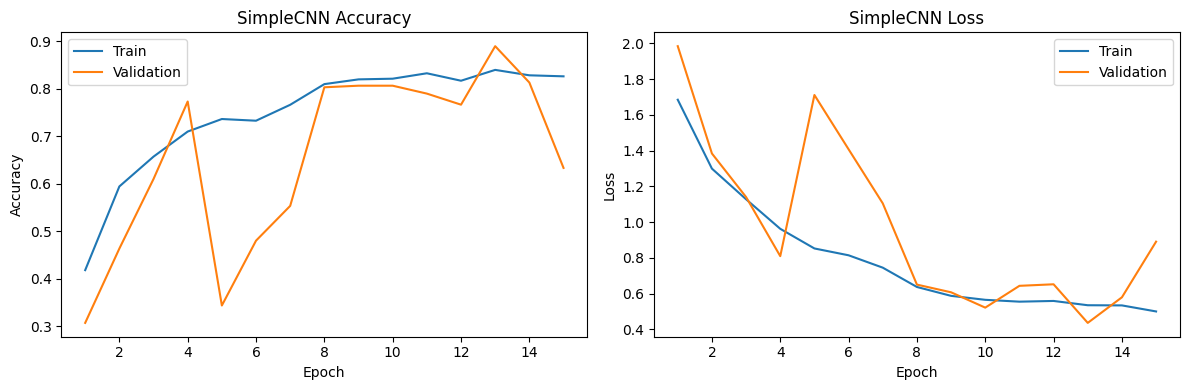

\n========== ResNet18_scratch ==========
ResNet18_scratch | Epoch 1/15 | train loss=1.2474, acc=0.5521 | val loss=4.6246, acc=0.2800 | lr=1.00e-03
ResNet18_scratch | Epoch 2/15 | train loss=0.7674, acc=0.7286 | val loss=8.9976, acc=0.2000 | lr=1.00e-03
ResNet18_scratch | Epoch 3/15 | train loss=0.7053, acc=0.7521 | val loss=21.8547, acc=0.1000 | lr=1.00e-03
ResNet18_scratch | Epoch 4/15 | train loss=0.6349, acc=0.7721 | val loss=2.9385, acc=0.3833 | lr=1.00e-03
ResNet18_scratch | Epoch 5/15 | train loss=0.6097, acc=0.7864 | val loss=15.8127, acc=0.2000 | lr=1.00e-03
ResNet18_scratch | Epoch 6/15 | train loss=0.5940, acc=0.7893 | val loss=24.4401, acc=0.1800 | lr=1.00e-03
ResNet18_scratch | Epoch 7/15 | train loss=0.4870, acc=0.8379 | val loss=1.7324, acc=0.4967 | lr=1.00e-03
ResNet18_scratch | Epoch 8/15 | train loss=0.5660, acc=0.8057 | val loss=1.1304, acc=0.6767 | lr=1.00e-03
ResNet18_scratch | Epoch 9/15 | train loss=0.5628, acc=0.8021 | val loss=21.8511, acc=0.1000 | lr=1.00e-03
R

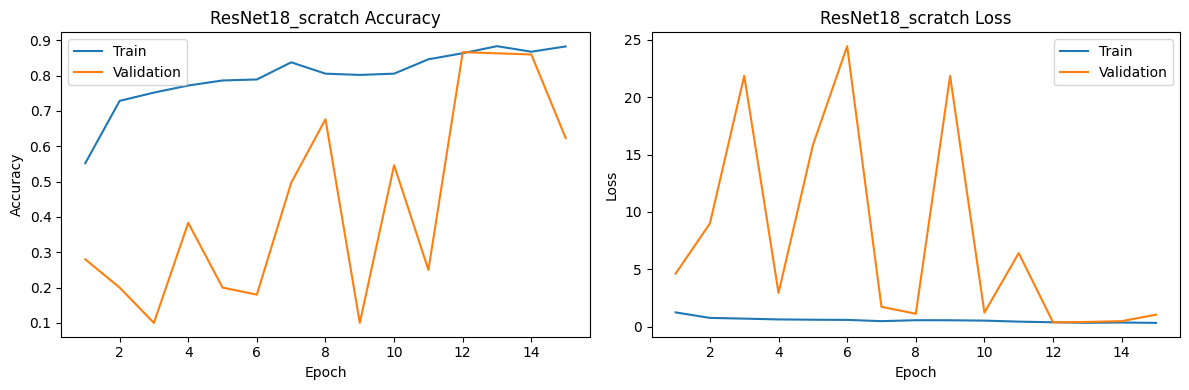

\n========== MobileNetV2_scratch ==========
MobileNetV2_scratch | Epoch 1/15 | train loss=1.6352, acc=0.3714 | val loss=3.6125, acc=0.1000 | lr=1.00e-03
MobileNetV2_scratch | Epoch 2/15 | train loss=0.9071, acc=0.6664 | val loss=0.5722, acc=0.8233 | lr=1.00e-03
MobileNetV2_scratch | Epoch 3/15 | train loss=0.7825, acc=0.7179 | val loss=1.7673, acc=0.5100 | lr=1.00e-03
MobileNetV2_scratch | Epoch 4/15 | train loss=0.6888, acc=0.7521 | val loss=3.5014, acc=0.3333 | lr=1.00e-03
MobileNetV2_scratch | Epoch 5/15 | train loss=0.6172, acc=0.7736 | val loss=2.1345, acc=0.4767 | lr=5.00e-04
MobileNetV2_scratch | Epoch 6/15 | train loss=0.4678, acc=0.8357 | val loss=0.5308, acc=0.8167 | lr=5.00e-04
MobileNetV2_scratch | Epoch 7/15 | train loss=0.4447, acc=0.8357 | val loss=0.3265, acc=0.8900 | lr=5.00e-04
MobileNetV2_scratch | Epoch 8/15 | train loss=0.3662, acc=0.8729 | val loss=0.3997, acc=0.8533 | lr=5.00e-04
MobileNetV2_scratch | Epoch 9/15 | train loss=0.3380, acc=0.8779 | val loss=0.8536, 

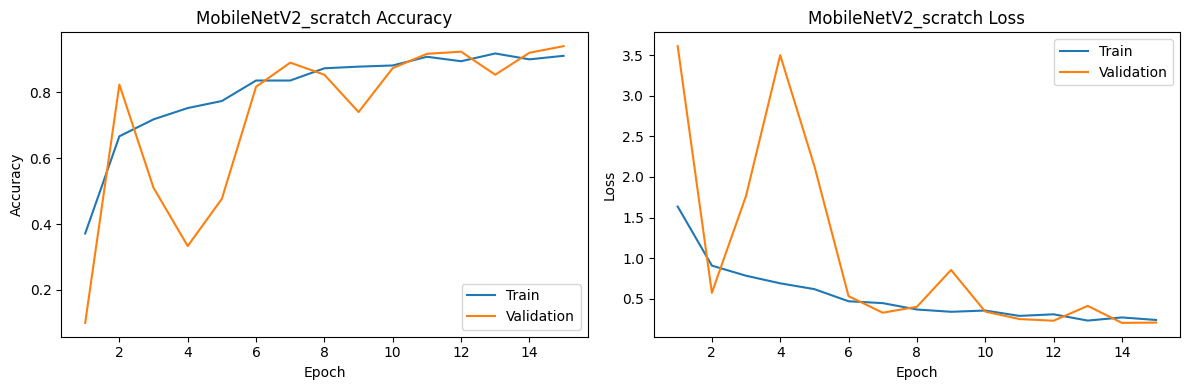

In [14]:
baseline_models = {}
baseline_histories = {}
baseline_training_times = {}

for model_name, builder in model_builders.items():
    print("\\n==========", model_name, "==========")
    trained_model, history, training_seconds = train_model(
        builder(), model_name
    )
    baseline_models[model_name] = trained_model
    baseline_histories[model_name] = history
    baseline_training_times[model_name] = training_seconds

    plot_history(history, model_name)

## 8. Test evaluation, classification reports and confusion matrices

\n SimpleCNN
               precision    recall  f1-score   support

         Aush       1.00      0.93      0.97        30
        BR-28       0.95      0.60      0.73        30
        BR-29       1.00      0.73      0.85        30
        Beroi       0.94      1.00      0.97        30
    Chinigura       0.97      1.00      0.98        30
    Ghee Bhog       0.86      0.83      0.85        30
 Katari Najir       0.76      0.93      0.84        30
Katari Siddho       0.72      0.87      0.79        30
      Miniket       0.94      1.00      0.97        30
       Swarna       0.76      0.87      0.81        30

     accuracy                           0.88       300
    macro avg       0.89      0.88      0.87       300
 weighted avg       0.89      0.88      0.87       300



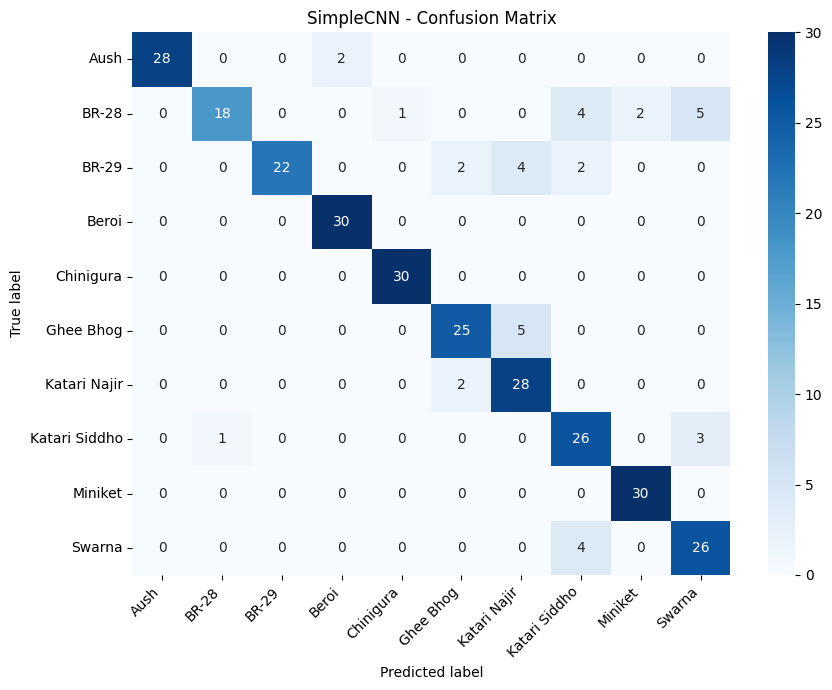

\n ResNet18_scratch
               precision    recall  f1-score   support

         Aush       0.94      1.00      0.97        30
        BR-28       0.77      0.77      0.77        30
        BR-29       0.78      0.97      0.87        30
        Beroi       1.00      0.93      0.97        30
    Chinigura       1.00      0.97      0.98        30
    Ghee Bhog       1.00      0.50      0.67        30
 Katari Najir       0.65      0.93      0.77        30
Katari Siddho       1.00      0.63      0.78        30
      Miniket       1.00      0.97      0.98        30
       Swarna       0.71      0.90      0.79        30

     accuracy                           0.86       300
    macro avg       0.88      0.86      0.85       300
 weighted avg       0.88      0.86      0.85       300



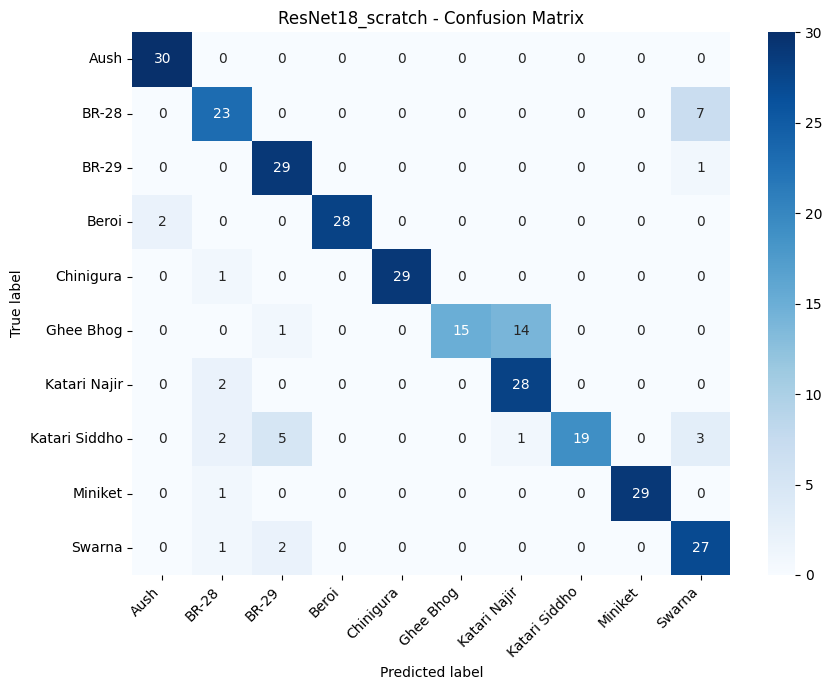

\n MobileNetV2_scratch
               precision    recall  f1-score   support

         Aush       1.00      1.00      1.00        30
        BR-28       0.83      0.83      0.83        30
        BR-29       0.91      0.97      0.94        30
        Beroi       1.00      1.00      1.00        30
    Chinigura       1.00      0.97      0.98        30
    Ghee Bhog       0.83      0.83      0.83        30
 Katari Najir       0.83      0.83      0.83        30
Katari Siddho       1.00      0.90      0.95        30
      Miniket       0.94      1.00      0.97        30
       Swarna       0.90      0.90      0.90        30

     accuracy                           0.92       300
    macro avg       0.92      0.92      0.92       300
 weighted avg       0.92      0.92      0.92       300



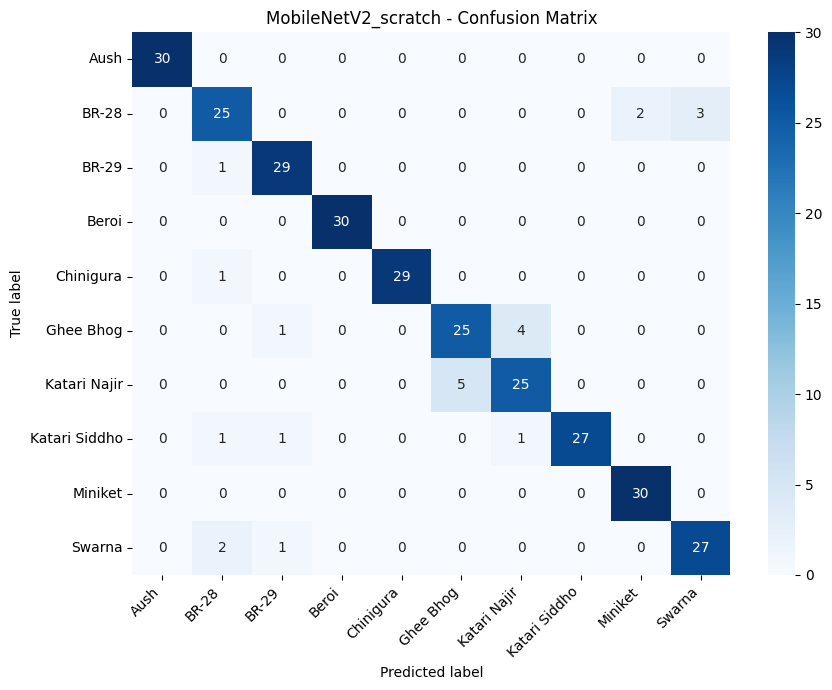

,Model,Accuracy,Precision_macro,Recall_macro,F1_macro,Precision_weighted,Recall_weighted,F1_weighted,Training_time_seconds,Parameters,Trainable_parameters,Model_size_MB
2,MobileNetV2_scratch,0.923333,0.924375,0.923333,0.923365,0.924375,0.923333,0.923365,276.609391,2236682,2236682,8.769847
0,SimpleCNN,0.876667,0.889586,0.876667,0.874911,0.889586,0.876667,0.874911,273.586704,391946,391946,1.509339
1,ResNet18_scratch,0.856667,0.884964,0.856667,0.853512,0.884964,0.856667,0.853512,271.847326,11181642,11181642,42.731822


In [15]:
baseline_results = []

for model_name, model in baseline_models.items():
    metrics = evaluate_model(model, model_name)
    info = model_information(model)
    baseline_results.append({
        **metrics,
        "Training_time_seconds": baseline_training_times[model_name],
        **info
    })

baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df.sort_values("F1_macro", ascending=False))

## 9. Save models, metrics, label map and split manifests

In [16]:
OUTPUT_DIR = "/content/task2_baseline_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

baseline_results_df.to_csv(
    f"{OUTPUT_DIR}/baseline_results.csv", index=False
)

with open(f"{OUTPUT_DIR}/label_map.json", "w") as file:
    json.dump(class_to_idx, file, indent=2)

for model_name, model in baseline_models.items():
    safe_name = model_name.lower().replace(" ", "_")
    torch.save(model.state_dict(), f"{OUTPUT_DIR}/{safe_name}_best.pth")

for split_name, frame in [
    ("train", train_df), ("validation", val_df), ("test", test_df)
]:
    frame.to_csv(f"{OUTPUT_DIR}/{split_name}_split.csv", index=False)

with open(f"{OUTPUT_DIR}/experiment_config.json", "w") as file:
    json.dump({
        "seed": SEED,
        "image_size": IMG_SIZE,
        "batch_size": BATCH_SIZE,
        "max_epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "split": "70/15/15 stratified; original images only",
        "pretrained_weights": False,
        "classes": class_names
    }, file, indent=2)

print("Saved outputs to:", OUTPUT_DIR)

Saved outputs to: /content/task2_baseline_outputs


## 10. Download baseline outputs

In [17]:
shutil.make_archive(
    "/content/Group06_RiceVarities_task2_baseline_outputs",
    "zip",
    OUTPUT_DIR
)
from google.colab import files
files.download("/content/Group06_RiceVarities_task2_baseline_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>